<a href="https://colab.research.google.com/github/GabrielC51/evolucao-diferencial-com-aplicacao-ao-pcv/blob/main/evolucao_diferencial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evolução Diferencial

### 1 - Introdução

Este Colab é a entrega da atividade da aula 3 do núcleo básico de Otimização da LIAO, complementar à entrega da atividade da aula 2. Dividi este arquivo em uma parte teórica, baseada no [slide da aula 2](https://canva.link/wzifadc4r7u4fus), e uma parte prática, com implementações da Evolução Diferencial.

### 2 - O que é Evolução Diferencial

A Evolução Diferencial, ou Differential Evolution (DE), é um algoritmo evolucionário que usa a diferença entre vetores de valores em ponto flutuante (que representam a população) como direção para realizar uma busca populacional.

A DE é uma meta-heurística populacional para otimização global em domínios contínuos. Ela atua sobre uma lógica de caixa preta, o que dispensa gradientes ou derivadas analíticas.

### 3 - Taxonomia

Na taxonomia das meta-heurísticas de Otimização, a Evolução se encaixa no ramo das meta-heurísticas baseadas em população, mais especificamente nos Algoritmos Evolucionários (EAs), onde divide espaço com outras meta-heurísticas famosas, como o Algoritmo Genético (GA) e a Estratégia Evolutiva (ES).

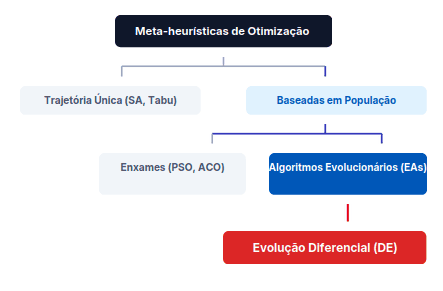

### 4 - História

A Evolução Diferencial nasceu como uma proposta de Rainer Storn (UC Berkeley) e Kenneth Price (pesquisador independente) em 1995, quando lançaram a primeira versão do algoritmo. Em 1996, o DE venceu o IEEE CEC 1996 (competição de otimização real), onde enfrentou algoritmos muito mais complexos e se destacou por sua simplicidade: muitos dos outros concorrentes tinham 10 parâmetros ou mais, enquanto o DE tinha apenas 2.

Em 1997, foi publicado o artigo "*Differential Evolution – A Simple and Efficient Heuristic for Global Optimization over Continuous Spaces*". Atualmente, ela é uma das meta-heurísticas mais citadas e está disponível nativamente em bibliotecas como SciPy.

### 5 - Evolução Diferencial vs. Algoritmo Genético

Outra meta-heurística muito popular é o Algoritmo Genético. Abaixo, temos uma tabela comparativa com suas principais diferenças:

| Critério | Algoritmo Genético | Evolução Diferencial |
|---|---|---|
| **Representação** | Bits ou permutações | Vetores numéricos reais (ponto flutuante) |
| **Motor Principal** | Cruzamento (Crossover) | Mutação Diferencial |
| **Perturbação** | Ruído aleatório fixo | Diferença escalada entre pares |
| **Seleção** | Probabilística (roleta/torneio) | Determinística 1:1 (gulosa) |

### 6 - Intuição, Mecanismo e Parâmetros

Esta seção condensa os três blocos centrais: a mutação diferencial, o mecanismo de 4 passos do DE e os parâmetros (F, CR e NP).

#### A Intuição Central: A mutação diferencial

O coração do DE é a mutação diferencial. Em vez de perturbar uma solução com ruído aleatório (como no GA), o DE usa a diferença entre vetores da própria população como direção de busca:

$$v = x_a + F \cdot (x_b - x_c)$$

- `x_a`, `x_b`, `x_c` são três vetores distintos da população (diferentes do alvo)
- `F` é o fator de escala (controla o tamanho do passo)
- `(x_b − x_c)` é a **direção** extraída da população

#### Exemplo numérico em 2D

Suponha a população:

| Vetor | Coordenadas |
|:---|:---|
| x₁ (alvo) | (1, 2) |
| x₂ | (3, 5) |
| x₃ | (4, 1) |
| x₄ | (2, 6) |

Com `F = 0.5`, `x_a = x₂`, `x_b = x₃`, `x_c = x₄`:

$$v = (3, 5) + 0.5 \cdot [(4, 1) - (2, 6)] = (3, 5) + 0.5 \cdot (2, -5) = (4, 2.5)$$

No início, temos uma população dispersa, com diferenças muito grandes, o que torna os passos grandes — ideal para a exploração. À medida que a população converge, as diferenças ficam menores e os passos também; nesse momento, ocorre a etapa de intensificação. Esse processo ocorre sem ajustes manuais, ou seja, é autoadaptativo.

#### Mecanismo de 4 Passos

1. **Inicialização**

População de `NP` vetores aleatórios no espaço de busca.
> `NP` típico: 5 a 10 vezes a dimensão do problema.

2. **Mutação diferencial**
Para cada alvo `x_i`, escolhem-se **3 vetores distintos** `x_a`, `x_b`, `x_c`:
$$v = x_a + F \cdot (x_b - x_c)$$

3. **Cruzamento binomial**
Para cada dimensão, com probabilidade `CR`, adota-se o valor do mutante `v`; caso contrário, mantém-se o alvo `x_i`. Isso gera o vetor de teste `u`.
> Porém, pelo menos 1 dos índices do vetor mutante é sorteado para ser herdado pelo vetor de teste independente do resultado do primeiro sorteio, garantindo que o vetor de teste não seja igual ao alvo.

4. **Seleção gulosa 1-para-1**
Se `f(u) < f(x_i)`, `u` substitui `x_i` na próxima geração. Caso contrário, `x_i` permanece.

#### Exemplo numérico do cruzamento

Alvo `x₁ = (1, 2)`, mutante `v = (4, 2.5)`, `CR = 0.7`:

| Dimensão | Sorteio | Ação | Resultado |
|:---|:---|:---|:---|
| 1 | 0.3 < 0.7 | pega `v1` | 4 |
| 2 | 0.8 ≥ 0.7 | mantém `x12` | 2 |

**Teste:** `u = (4, 2)`. Se `f(4,2) < f(1,2)` &rarr; substitui.

#### Os Parâmetros: F, CR e NP

| Parâmetro | O que controla | Faixa típica | Efeito |
|:---|:---|:---|:---|
| **F** (fator de escala) | Tamanho do passo na mutação | 0.4–1.0 | F alto &rarr; exploração; F baixo &rarr; intensificação |
| **CR** (taxa de cruzamento) | Quanto do mutante entra no trial | 0.5–1.0 | CR alto &rarr; trial &asymp; mutante; CR baixo &rarr; trial &asymp; alvo |
| **NP** (tamanho da população) | Diversidade | 5–10X dimensão | NP alto &rarr; exploração; NP baixo &rarr; convergência rápida |

**Valores clássicos:** `F = 0.5`, `CR = 0.9`, `NP = 50`

**Variantes modernas:** jDE, SaDE, SHADE, L-SHADE — autoadaptam F e CR durante a execução.

Melhor solução: [-3.68784714e-09 -2.68216905e-09]
Melhor fitness: 0.0000


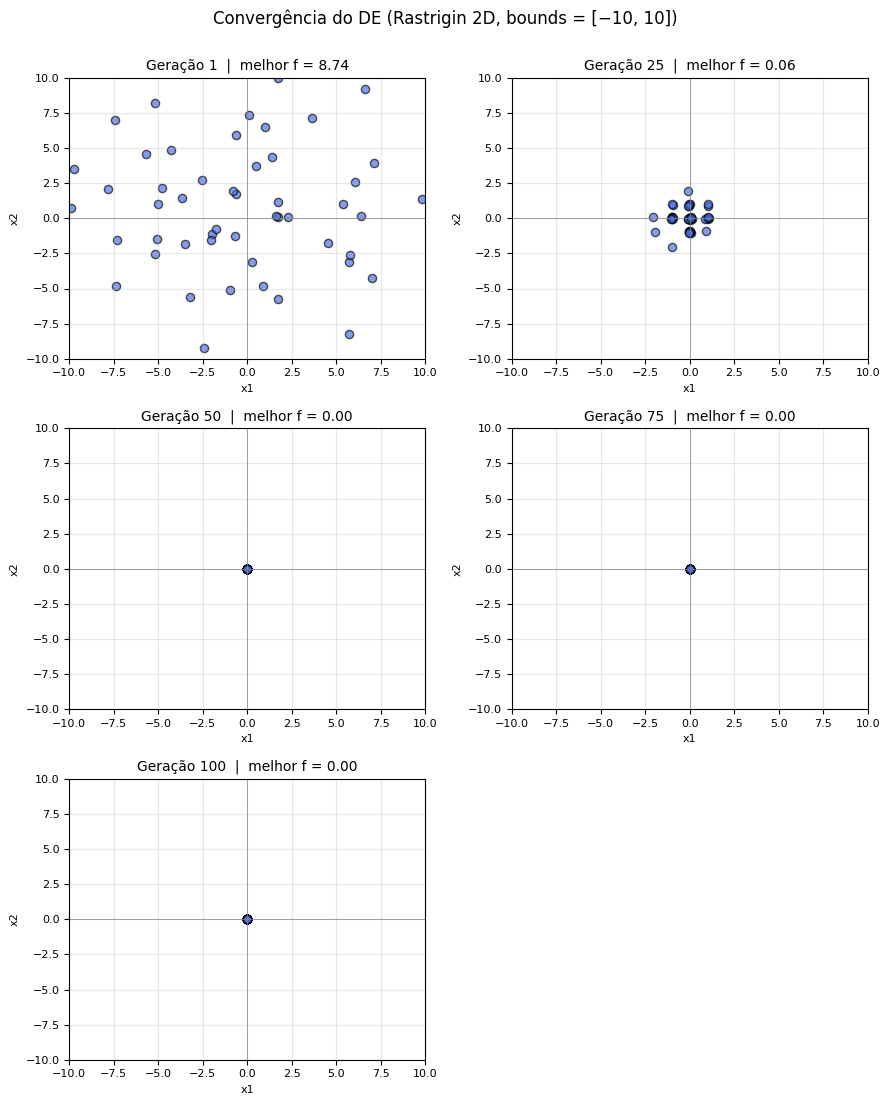

In [ ]:
# ============================================================
# DE DIDÁTICO + VISUALIZAÇÃO
# Gerações Exibidas: 1, 25, 50, 75, 100
# Função: Rastrigin (multimodal - muitos mínimos locais)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

#1 - Função-objetivo
def rastrigin(x):
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))

#2 - Parâmetros, dimensões e espaço de busca
NP, F, CR, G = 50, 0.9, 0.3, 100
dim = 2
bounds = (-10, 10)

#3 - Inicialização
pop = np.random.uniform(bounds[0], bounds[1], (NP, dim))
fitness = np.array([rastrigin(ind) for ind in pop])
historico, melhores = [], []

#4 - Loop principal
for g in range(G):
    for i in range(NP):
        # Mutação diferencial
        a, b, c = np.random.choice([j for j in range(NP) if j != i], 3, replace=False)
        v = pop[a] + F * (pop[b] - pop[c])
        v = np.clip(v, bounds[0], bounds[1])

        # Cruzamento binomial
        u = pop[i].copy()
        j_rand = np.random.randint(dim)
        for d in range(dim):
            if np.random.rand() < CR or d == j_rand:
                u[d] = v[d]

        # Seleção gulosa 1-para-1
        f_u = rastrigin(u)
        if f_u < fitness[i]:
            pop[i], fitness[i] = u, f_u

    historico.append(pop.copy())
    melhores.append(fitness.min())

print(f"Melhor solução: {pop[np.argmin(fitness)]}")
print(f"Melhor fitness: {fitness.min():.4f}")

# ---------- 5. Visualização ----------
geracoes_alvo = [1, 25, 50, 75, 100]
fig, axes = plt.subplots(3, 2, figsize=(9, 11))
axes_flat = axes.flatten()

for idx, gen in enumerate(geracoes_alvo):
    ax = axes_flat[idx]
    snap = historico[gen - 1]
    ax.scatter(snap[:, 0], snap[:, 1],
               c='royalblue', alpha=0.65, edgecolors='k', s=35)
    ax.set_title(f'Geração {gen}  |  melhor f = {melhores[gen-1]:.2f}', fontsize=10)
    ax.set_xlim(bounds); ax.set_ylim(bounds)
    ax.set_xlabel('x1', fontsize=8); ax.set_ylabel('x2', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.grid(alpha=0.3)

axes_flat[-1].axis('off')

plt.suptitle('Convergência do DE (Rastrigin 2D, bounds = [−10, 10])',
             fontsize=12, y=1.00)
plt.tight_layout()
plt.show()

differential_evolution step 1: f(x)= 6.535212505628747
differential_evolution step 2: f(x)= 1.9854823164876905
differential_evolution step 3: f(x)= 0.06006313653747952
differential_evolution step 4: f(x)= 0.06006313653747952
differential_evolution step 5: f(x)= 0.06006313653747952
differential_evolution step 6: f(x)= 0.06006313653747952
differential_evolution step 7: f(x)= 0.007615215034771694
differential_evolution step 8: f(x)= 0.007615215034771694
differential_evolution step 9: f(x)= 0.002365689066316179
differential_evolution step 10: f(x)= 0.002365689066316179
differential_evolution step 11: f(x)= 0.002365689066316179
differential_evolution step 12: f(x)= 0.002365689066316179
differential_evolution step 13: f(x)= 0.0003107890329978602
differential_evolution step 14: f(x)= 0.0003107890329978602
differential_evolution step 15: f(x)= 7.296122513977821e-05
differential_evolution step 16: f(x)= 4.724738062122924e-06
differential_evolution step 17: f(x)= 8.198218139909841e-07
differenti

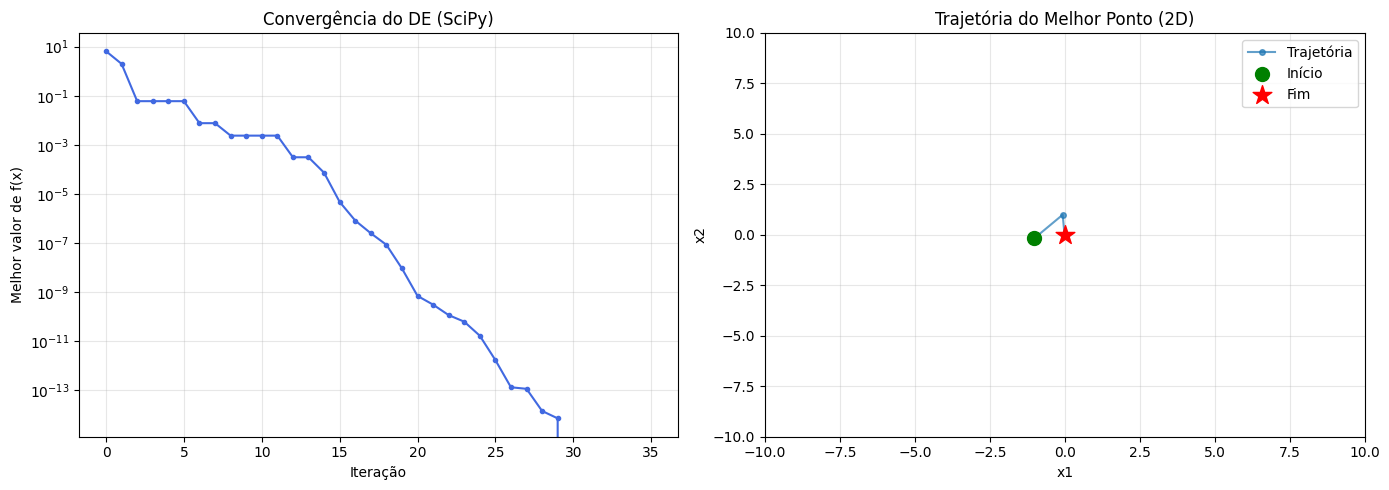

In [ ]:
# ============================================================
# DE NA LIB SCIPY + VISUALIZAÇÃO
# Função: Rastrigin (multimodal - muitos mínimos locais)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

#1 - Função-objetivo
def rastrigin(x):
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))

# 2 - Listas para armazenar o histórico a cada iteração
historico_x = []
historico_f = []

# 3 - Função de callback para registrar o progresso
def callback(x, convergence):
    historico_x.append(x.copy())
    historico_f.append(rastrigin(x))

# 4 - Executa a Evolução Diferencial do SciPy
bounds = [(-10, 10), (-10, 10)]
resultado = differential_evolution(
    rastrigin,            # Define a função objetivo
    bounds,               # Define o espaço de busca
    strategy='best1bin',  # Estrategia
    maxiter=100,          # Gerações
    popsize=50,           # População
    mutation=0.5,         # Fator de Escala (F) default: (0.5 - 1) sorteado por geração
    recombination=0.9,    # Taxa de Cruzamento (CR) default: 0.7
    tol=0.01,             # Tolerancia - para as interações caso o desvio padrão <= 1% da média - default: 0.01
    callback=callback,    # Habilita callback
    disp=True             # Habilita saída no terminal para o callback default: False
)

# 5 - Exibição
print("\n--- Resultado Final ---")
print(f"Melhor solução encontrada: {resultado.x}")
print(f"Valor da função objetivo: {resultado.fun:.6f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Curva de convergência
ax1.plot(historico_f, marker='o', markersize=3, linestyle='-', color='royalblue')
ax1.set_title('Convergência do DE (SciPy)')
ax1.set_xlabel('Iteração')
ax1.set_ylabel('Melhor valor de f(x)')
ax1.grid(alpha=0.3)
ax1.set_yscale('log')

# Gráfico 2: Trajetória do melhor ponto no espaço de busca 2D
historico_x = np.array(historico_x)
ax2.plot(historico_x[:, 0], historico_x[:, 1], marker='o', markersize=4, linestyle='-', alpha=0.7, label='Trajetória')
ax2.scatter(historico_x[0, 0], historico_x[0, 1], color='green', s=100, zorder=5, label='Início')
ax2.scatter(historico_x[-1, 0], historico_x[-1, 1], color='red', marker='*', s=200, zorder=5, label='Fim')
ax2.set_title('Trajetória do Melhor Ponto (2D)')
ax2.set_xlabel('x1')
ax2.set_ylabel('x2')
ax2.set_xlim(bounds[0])
ax2.set_ylim(bounds[1])
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

# Aplicação ao Problema do Caixeiro Viajante

Para aplicar a DE ao Problema do Caixeiro Viajante (PCV), é necessário realizar algumas adaptações. Como citado nos blocos anteriores, o DE é um algoritmo que funciona no domínio contínuo através de um vetor de números reais, enquanto o PCV é um problema de domínio combinatório/discreto.

Para tornar o DE aplicável ao PCV, é preciso fazer algumas adaptações no algoritmo base. A forma mais simples e didática de fazer isso é através da codificação por chave aleatória (ou *Random Key*). Nela, o DE continua trabalhando com vetores de números reais, mas a rota é decodificada ordenando esses valores. Isso mantém a parte essencial do DE (mutação diferencial e cruzamento binomial) intacta.

Nessa versão, o vetor deixa de ser o principal avaliado e passa a ser um conjunto de chaves (uma por cidade), sendo a rota obtida a partir da ordenação dessas chaves. A avaliação também muda: ao invés de avaliar diretamente o vetor, é necessário decodificar o vetor em uma rota para avaliar o *fitness* (que, no caso do PCV, é a distância total da rota).

Melhor distância encontrada: 268.45
Melhor rota: [5, 6, 1, 4, 2, 3, 9, 8, 0, 7]



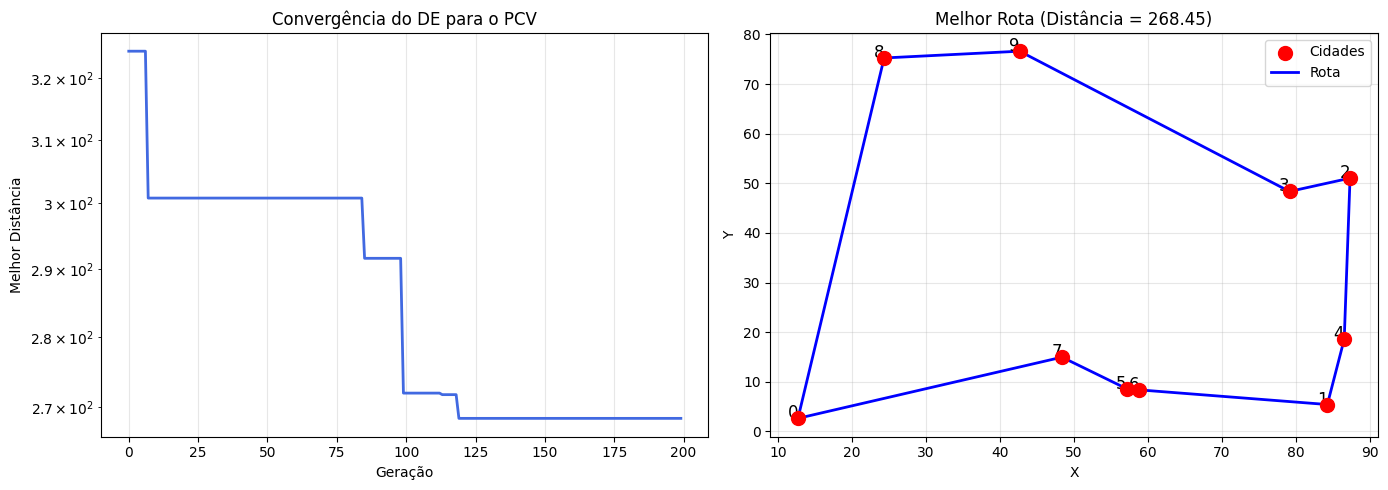

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

# ============================================================
# 1 - DEFINIÇÃO DO PROBLEMA (PCV)
# ============================================================
def gerar_cidades(n=10):
    #Gera coordenadas aleatórias para n cidades.
    return np.random.rand(n, 2) * 100

def matriz_distancias(cidades):
    #Calcula a matriz de distâncias euclidianas entre todas as cidades.
    n = len(cidades)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            D[i, j] = np.linalg.norm(cidades[i] - cidades[j])
    return D

def fitness_rota(rota, D):
    """Calcula a distância total de uma rota (permutação)."""
    distancia = 0
    for i in range(len(rota)):
        distancia += D[rota[i], rota[(i + 1) % len(rota)]]
    return distancia

# ============================================================
# 2 - DECODIFICAÇÃO (RANDOM KEY -> PERMUTAÇÃO)
# ============================================================
def decodificar(vetor):
    # Converte um vetor de números reais em uma permutação de índices.
    return list(np.argsort(vetor))

# ============================================================
# 3 - EVOLUÇÃO DIFERENCIAL ADAPTADA
# ============================================================
def de_pcv(D, num_cidades, NP=50, F=0.5, CR=0.9, G=200):
    #Executa o DE com codificação Random Key para o PCV.
    dim = num_cidades
    pop = np.random.rand(NP, dim)  # População de vetores reais
    fitness = np.array([fitness_rota(decodificar(ind), D) for ind in pop])

    historico = []  # Para armazenar o melhor fitness de cada geração

    for g in range(G):
        for i in range(NP):
            idxs = [j for j in range(NP) if j != i]
            a, b, c = np.random.choice(idxs, 3, replace=False)
            v = pop[a] + F * (pop[b] - pop[c])

            u = pop[i].copy()
            j_rand = np.random.randint(dim)
            for j in range(dim):
                if np.random.rand() < CR or j == j_rand:
                    u[j] = v[j]

            rota_u = decodificar(u)
            f_u = fitness_rota(rota_u, D)
            if f_u < fitness[i]:
                pop[i] = u
                fitness[i] = f_u

        historico.append(fitness.min())

    melhor_idx = np.argmin(fitness)
    melhor_rota = decodificar(pop[melhor_idx])
    return melhor_rota, fitness[melhor_idx], historico

# ============================================================
# 4 - EXECUÇÃO E VISUALIZAÇÃO
# ============================================================
if __name__ == "__main__":
    # Parâmetros
    N_CIDADES = 10
    cidades = gerar_cidades(N_CIDADES)
    D = matriz_distancias(cidades)

    # Roda o DE
    melhor_rota, melhor_dist, hist = de_pcv(D, N_CIDADES, NP=50, F=0.5, CR=0.9, G=200)

    print(f"Melhor distância encontrada: {melhor_dist:.2f}")
    print(f"Melhor rota: {list(map(int, melhor_rota))}", end='\n\n')
    # --- Plotagem ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico 1: Convergência
    ax1.plot(hist, color='royalblue', linewidth=2)
    ax1.set_title("Convergência do DE para o PCV")
    ax1.set_xlabel("Geração")
    ax1.set_ylabel("Melhor Distância")
    ax1.grid(alpha=0.3)
    ax1.set_yscale('log')

    # Gráfico 2: Melhor rota encontrada
    rota_plot = melhor_rota + [melhor_rota[0]]
    ax2.scatter(cidades[:, 0], cidades[:, 1], c='red', s=100, zorder=5, label='Cidades')
    ax2.plot(cidades[rota_plot, 0], cidades[rota_plot, 1], 'b-', linewidth=2, label='Rota')
    for i, (x, y) in enumerate(cidades):
        ax2.text(x, y, str(i), fontsize=12, ha='right')
    ax2.set_title(f"Melhor Rota (Distância = {melhor_dist:.2f})")
    ax2.set_xlabel("X")
    ax2.set_ylabel("Y")
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# Referências

Todas as fontes utilizadas na elaboração deste notebook e da apresentação sobre Evolução Diferencial (DE), organizadas por categoria.

---

## Fontes Primárias e Fundamentais

### Paper Seminal (1997)
> STORN, R.; PRICE, K. **Differential Evolution – A Simple and Efficient Heuristic for Global Optimization over Continuous Spaces**. *Journal of Global Optimization*, v. 11, n. 4, p. 341–359, 1997.

### Survey Abrangente (2011)
> DAS, S.; SUGANTHAN, P. N. **Differential Evolution: A Survey of the State-of-the-Art**. *IEEE Transactions on Evolutionary Computation*, v. 15, n. 1, p. 4–31, 2011.

### Livro de Referência (2005)
> PRICE, K. V.; STORN, R. M.; LAMPINEN, J. A. **Differential Evolution: A Practical Approach to Global Optimization**. Springer, 2005.

---

## Documentação Técnica e Implementação

### Documentação Oficial do SciPy
> SCIENTIFIC PYTHON (SciPy). **scipy.optimize.differential_evolution**. SciPy v1.18.0 Manual. Disponível em: <https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.differential_evolution.html>.

---

## Aplicação em Problemas de Permutação (PCV/TSP)

### Codificação por Chave Aleatória (2022)
> UHER, V.; KROMER, P. **Lehmer Encoding for Evolutionary Algorithms on Traveling Salesman Problem**. *ICMLT 2022*.

### Variantes Discretas do DE
> **Novel Random Key Encoding Schemes for the Differential Evolution of Permutation Problems**.

> **A Differential Evolution Algorithm for Generic Combinatorial Optimization Problems**.

---

## Teoria e Contexto

### Teorema No Free Lunch (1997)
> WOLPERT, D. H.; MACREADY, W. G. **No Free Lunch Theorems for Optimization**. *IEEE Transactions on Evolutionary Computation*, v. 1, n. 1, p. 67–82, 1997.

---

## Fontes de Apoio e Contexto Geral

> **Wikipedia** — *Differential Evolution*. Disponível em: <https://en.wikipedia.org/wiki/Differential_evolution>.